# Backlog v5: model strength, source attribution and preference prediction

This notebook separates the known-name diagnostic from practical text-derived
source predictions. All comparisons use the same exploratory development rows.
Models and learned stages respect their declared prompt-grouped fitting folds.
The best official score is a separate reference; no submission is made here.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
REPO=Path.cwd().resolve()
if not (REPO/'GOAL.md').exists():REPO=REPO.parent
RESULTS=REPO/'results/span_005'
def read(name):return json.loads((RESULTS/name).read_text())
FIGURES=Path.home()/'database/llm_classification_finetuning/runs/span_005/figures'
FIGURES.mkdir(parents=True,exist_ok=True)
def save(fig,name):
    for suffix in ['png','svg']:fig.savefig(FIGURES/(name+'.'+suffix),dpi=160,bbox_inches='tight')
    plt.show()
e06=read('E06_results.json');e07=read('E07_results.json');h45=read('H45_results.json')
registry=json.loads((REPO/'backlog/hypotheses.json').read_text())
v5=next(v for v in registry['versions'] if v['number']==5);items={i['id']:i for i in registry['items']}
print('v5 state:',v5['state'],'focus:',v5['focus_ids'])
display(pd.DataFrame([{'task':k,'status':items[k]['status'],'title':items[k]['title']} for k in v5['focus_ids']]))
print('Original clock:',read('activation.json')['started_at'],'deadline:',read('activation.json')['deadline'])
print('Coverage:',e06['train_rows'],'training rows;',e06['rows'],'development rows;',e06['groups'],'development prompt groups')
print('Official log loss unchanged:',h45['official_score_unchanged'])


v5 state: closed focus: ['E06', 'E07', 'H45']


,task,status,title
0,E06,done,Estimate model strength and true-identity resi...
1,E07,done,Predict source-model probabilities from respon...
2,H45,done,Add inferred source-model features to LoRA pre...


Original clock: 2026-11-05T07:17:10+00:00 deadline: 2026-11-07T07:17:10+00:00
Coverage: 45985 training rows; 5746 development rows; 5211 development prompt groups
Official log loss unchanged: 0.95481


## E06: opponent-adjusted strength and the known-name diagnostic

Ratings fit original training votes with opponent adjustment, shrinkage and ties.
Their intervals are conditional prompt-cluster sandwich normal approximations,
not intrinsic quality estimates. Known development identities are diagnostic only.


,model,answers,wins,ties,raw_win_rate,rating,conditional_cluster_normal_interval_95
0,gpt-4-1106-preview,5939,3268,1653,0.550261,1.566252,"[1.496452, 1.636052]"
1,gpt-4-0125-preview,930,478,290,0.513978,1.324275,"[1.194749, 1.453802]"
2,gpt-4-0314,3268,1582,953,0.484088,1.052870,"[0.970552, 1.135187]"
3,gpt-4-0613,4900,1944,1483,0.396735,0.826604,"[0.756636, 0.896571]"
4,claude-1,3176,1389,947,0.437343,0.723002,"[0.639925, 0.806079]"
5,mistral-medium,2638,964,876,0.365428,0.668660,"[0.580588, 0.756733]"
6,gpt-3.5-turbo-0314,1044,572,267,0.547893,0.639635,"[0.507212, 0.772058]"
7,claude-2.0,1972,756,576,0.383367,0.526235,"[0.423958, 0.628513]"
8,qwen1.5-72b-chat,450,173,151,0.384444,0.518462,"[0.359476, 0.677447]"
9,gemini-pro-dev-api,1201,386,368,0.321399,0.424937,"[0.301639, 0.548236]"


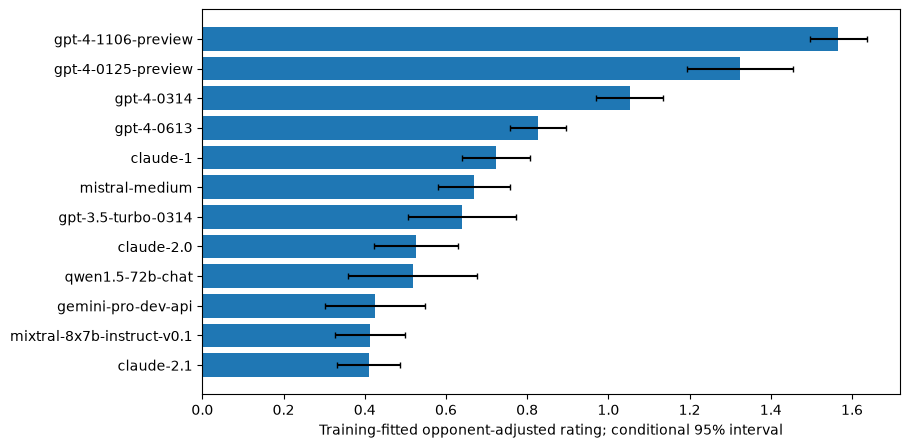

,method,log_loss,accuracy
0,calibration,0.953701,0.538810
1,style,0.954809,0.533763
2,oracle_strength,0.940456,0.550818
3,oracle_full,0.952212,0.544553
4,nested_selected,0.940456,0.550818
5,frozen_classifier,0.953971,0.537939
6,training_prior,1.097216,0.349112
7,uniform,1.098612,0.349112
8,majority_clipped_1e-12,17.984688,0.349112
9,strength_only,1.044275,0.442743


Information gate: {'passed': True, 'rule': 'Nested-oracle gain >0,95% upper bound >=0.001,and >=95% known-pair coverage; an information gate, not adoption.', 'evidence': {'gain': 0.013245621828178504, 'interval_95': [0.008967992635261404, 0.01751520024467121], 'groups': 5211, 'rows': 5746, 'replicates': 2000}}
Conditional prompt-cluster sandwich normal intervals at the penalized fit; not refitted bootstrap intervals, intrinsic skill, or correction for shrinkage/selection bias.


In [2]:
rank=pd.DataFrame(e06['rankings']);display(rank.head(12))
top=rank.head(12).iloc[::-1];rating=top['rating'].to_numpy();bounds=np.array(top['conditional_cluster_normal_interval_95'].tolist())
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(top['model'],rating,color='C0');ax.errorbar(rating,np.arange(len(top)),xerr=np.vstack([rating-bounds[:,0],bounds[:,1]-rating]),fmt='none',ecolor='black',capsize=2)
ax.set_xlabel('Training-fitted opponent-adjusted rating; conditional 95% interval')
save(fig,'source_strength_rankings')
display(pd.DataFrame([{'method':k,'log_loss':v['log_loss'],'accuracy':v['accuracy']} for k,v in e06['metrics'].items()]))
print('Information gate:',e06['gate'])
print(e06['ranking_uncertainty'])


## E07: infer sources from response text

Source-head comparisons use only training source labels. Prompt groups are held
out and duplicate answers purged from each fitting side. The cached embedding
head is a research control; the portable TF-IDF family is fixed before observing
development preference losses. Source identification accuracy is not preference
accuracy. Calibration is measured on raw probabilities without post-hoc fitting.


,family,source_log_loss,prior_loss,source_accuracy,top5,macro_recall,ECE,dev_source_log_loss_diagnostic,final_purged_answers
0,tfidf,2.938585,3.822561,0.270795,0.544939,0.129807,0.020971,2.856217,882
1,cached_embedding,3.704803,3.822561,0.099543,0.318778,0.044341,0.024318,3.679296,882


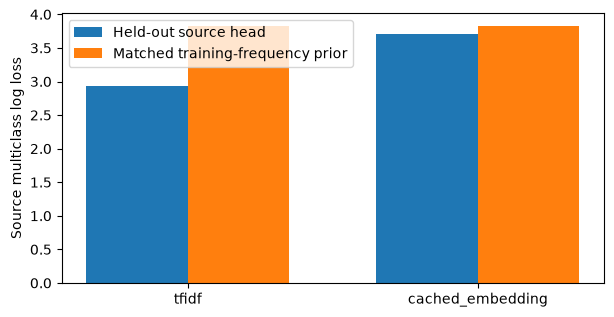

Practical family: tfidf gate: {'passed': True, 'rule': 'Portable TF-IDF OOF gain over prior >0; finite full coverage; measured conditional path<=25200s and RSS<6GiB.'}
Conditional classifier+source projection: 18849.344203891644 seconds
Conditional25000hidden rows, sequential classifier+CPU source stage,20%margin,600sreserve; classifier rate from frozen prior profile. Not a new end-to-end Kaggle run.


In [3]:
source_rows=[]
for name,r in e07['families'].items():
    source_rows.append({'family':name,'source_log_loss':r['oof']['log_loss'],'prior_loss':r['oof_prior']['log_loss'],
                       'source_accuracy':r['oof']['accuracy'],'top5':r['oof']['top5_accuracy'],
                       'macro_recall':r['oof']['macro_recall'],'ECE':r['oof']['ece_10_bins'],
                       'dev_source_log_loss_diagnostic':r['development_source_diagnostic']['log_loss'],
                       'final_purged_answers':r['final_fit']['purged_fit_answers']})
display(pd.DataFrame(source_rows))
fig,ax=plt.subplots(figsize=(7,3.5));x=np.arange(len(source_rows));width=.35
ax.bar(x-width/2,[r['source_log_loss'] for r in source_rows],width,label='Held-out source head')
ax.bar(x+width/2,[r['prior_loss'] for r in source_rows],width,label='Matched training-frequency prior')
ax.set_xticks(x,[r['family'] for r in source_rows]);ax.set_ylabel('Source multiclass log loss');ax.legend()
save(fig,'source_attribution')
print('Practical family:',e07['portable_family'],'gate:',e07['gate'])
print('Conditional classifier+source projection:',e07['projected_classifier_plus_source_seconds'],'seconds')
print(e07['projection_note'])


## H45: incremental preference value

The practical worker loads response text and inferred probabilities, without
development source-name columns. Every residual/calibration/selection stage fits
inside its appropriate groups. The oracle and practical results are separate.
Intervals condition on fitted OOF predictions; inspected development is exploratory.


,method,log_loss,accuracy,tie_loss,tie_recall,tie_auc
0,calibration,0.953701,0.538810,1.071183,0.365070,0.678936
1,style,0.954809,0.533763,1.073716,0.361690,0.677003
2,source_strength,0.952397,0.540898,1.072215,0.367887,0.677702
3,source_full,0.954611,0.537417,1.072731,0.369014,0.677125
4,shuffled_source,0.953985,0.540550,1.071353,0.369577,0.678712
5,nested_selected,0.953834,0.541072,1.074283,0.370704,0.674974
6,source_only,1.077106,0.419944,1.185446,0.000000,0.493160
7,frozen_classifier,0.953971,0.537939,1.065536,0.379155,0.679129
8,training_prior,1.097216,0.349112,1.174369,0.000000,0.500000
9,uniform,1.098612,0.349112,1.098612,0.000000,0.500000


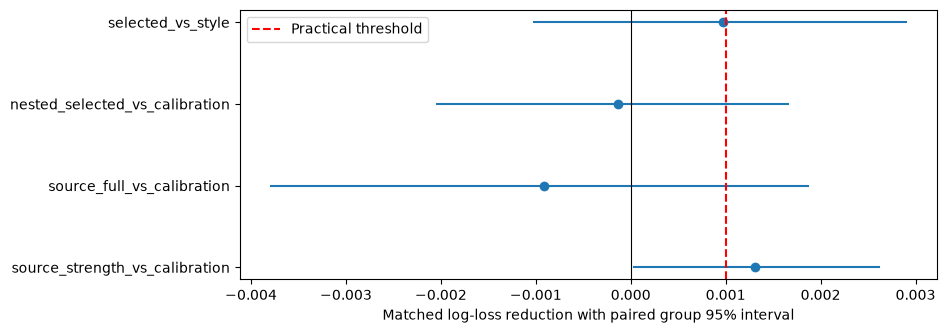

Adoption gate: {'passed': False, 'rule': 'Gain>=0.001 and paired95%lower bound>0 versus both calibration and style; no official submission in this span.'}
Oracle diagnostic gain: {'gain': 0.013245621828178504, 'interval_95': [0.008967992635261404, 0.01751520024467121], 'groups': 5211, 'rows': 5746, 'replicates': 2000}
Practical gain: {'gain': -0.00013304029496211917, 'interval_95': [-0.0020379657195243018, 0.001660322859250589], 'groups': 5211, 'rows': 5746, 'replicates': 2000}


In [4]:
display(pd.DataFrame([{'method':k,'log_loss':v['log_loss'],'accuracy':v['accuracy'],
                      'tie_loss':v['class_loss'][2],'tie_recall':v['class_recall'][2],'tie_auc':v['tie_auc']}
                     for k,v in h45['metrics'].items()]))
comparisons={k:v for k,v in h45['contrasts'].items() if k in ['source_strength_vs_calibration','source_full_vs_calibration','nested_selected_vs_calibration','selected_vs_style']}
fig,ax=plt.subplots(figsize=(9,3.5))
for i,(name,value) in enumerate(comparisons.items()):
    lo,hi=value['interval_95'];ax.plot([lo,hi],[i,i],color='C0');ax.scatter(value['gain'],i,color='C0')
ax.set_yticks(range(len(comparisons)),list(comparisons));ax.axvline(0,color='black',linewidth=.8)
ax.axvline(.001,color='red',linestyle='--',label='Practical threshold');ax.set_xlabel('Matched log-loss reduction with paired group 95% interval');ax.legend()
save(fig,'preference_source_gain')
print('Adoption gate:',h45['gate'])
print('Oracle diagnostic gain:',e06['contrasts']['nested_selected_vs_calibration'])
print('Practical gain:',h45['contrasts']['nested_selected_vs_calibration'])


## Resources, decisions and version handoff

GPU use and new submissions are zero. The first E06 loader failure is preserved;
the recovery recomputes canonical prompt hashes without unpickling. No numerical
guard, split or human vote changed. See the linked Markdown reports for limitations
and next-version work. Stop at the version boundary.


In [5]:
display(pd.DataFrame([{'task':r['task'],'cpu_seconds':r['cpu_elapsed_seconds'],'peak_rss_gib':r['peak_rss_gib']} for r in [e06,e07,h45]]))
print('E06 including conservative failure allowance:',e06['cpu_accounted_seconds_upper_bound'],'seconds')
for name in ['decisions.json','scientific_audit.json','terminal_audit.json']:
    if (RESULTS/name).exists():
        value=read(name)
        print(name,{k:v for k,v in value.items() if k not in ['artifact_sha256','tasks','jobs','inventory','old_snapshot_sha256']})
        if 'inventory' in value:print('Closing quota:',value['inventory']['quota'])
display(pd.DataFrame([{'version':v['number'],'state':v['state'],'tasks':len(v['item_ids']),'focus':v['focus_ids']} for v in registry['versions']]))
print('Standalone figures:',FIGURES)


,task,cpu_seconds,peak_rss_gib
0,E06,19.528303,0.639889
1,E07,1703.979103,3.701302
2,H45,24.704575,0.458611


E06 including conservative failure allowance: 79.52830333600286 seconds
decisions.json {'span': 5, 'focus': ['E06', 'E07', 'H45'], 'E06': {'status': 'done', 'information_gate_passed': True}, 'E07': {'status': 'done', 'portable_gate_passed': True}, 'H45': {'status': 'done', 'primary_adoption_gate_passed': False, 'primary_loss': 0.9538344653839755, 'primary_gain': {'gain': -0.00013304029496211917, 'interval_95': [-0.0020379657195243018, 0.001660322859250589], 'groups': 5211, 'rows': 5746, 'replicates': 2000}, 'fixed_strength_family_gain': {'gain': 0.0013048803163494612, 'interval_95': [3.704840767361772e-05, 0.0026182996958365153], 'groups': 5211, 'rows': 5746, 'replicates': 2000}, 'post_hoc_promotion': False}, 'best_official_log_loss': 0.95481, 'new_submissions': 0, 'gpu_seconds': 0, 'confirmation_used': False, 'experiment_elapsed_seconds': 1748.2119811230805, 'conservative_failure_allowance_seconds': 60, 'experiment_accounted_upper_seconds': 1808.2119811230805, 'scientific_audit_passed

,version,state,tasks,focus
0,1,closed,41,"[E00, H01, H09, H04, H11]"
1,2,closed,39,"[H40, E01, H03, H37, H42]"
2,3,closed,37,"[E03, H39, E02, H43]"
3,4,closed,35,"[E04, H44]"
4,5,closed,38,"[E06, E07, H45]"
5,6,active,37,[]
6,7,draft,0,[]


Standalone figures: /home/tarstars/database/llm_classification_finetuning/runs/span_005/figures
